### Run this notebook online

[![Open in Colab](https://img.shields.io/badge/Open_in-Colab-F9AB00?logo=googlecolab&logoColor=F9AB00)](https://colab.research.google.com/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/thesis/12_Naive_Sequential_Reference.ipynb)
[![Open in Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://www.kaggle.com/kernels/welcome?src=https%3A%2F%2Fgithub.com%2Fhosein-fanai%2FContinual-Learning-with-Diffusion-Vision-Transformers%2Fblob%2Fmain%2Ffiles%2Fnotebooks%2Fthesis%2F12_Naive_Sequential_Reference.ipynb)
[![Launch Binder](https://img.shields.io/badge/launch-binder-F5793A?logo=jupyter&logoColor=white)](https://mybinder.org/v2/gh/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/main?urlpath=lab%2Ftree%2Ffiles%2Fnotebooks%2Fthesis%2F12_Naive_Sequential_Reference.ipynb)

- **Google Colab:** open the notebook, select a GPU for training under **Runtime > Change runtime type**, then choose **Run all**.
- **Kaggle:** sign in and import the notebook, enable **Internet**, select a **GPU** accelerator for training, then **Run all**.
- **Binder:** opens a temporary CPU JupyterLab session. Use it to inspect the notebook or run small checks; full training needs more resources.
- **[Studio Lab](https://studiolab.sagemaker.aws/import/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/thesis/12_Naive_Sequential_Reference.ipynb) (existing accounts only):** start a runtime, copy the notebook to your project, select a Python **3.11–3.13** kernel, and set `RUNTIME = "studiolab"` in the first code cell before **Run all**. For CPU, also set `CUDA = False`.

The **first code cell** finds or downloads the repository and prepares TensorFlow **2.20** / Keras **3.11.2** before project imports. If setup requests a restart, restart the kernel and run all again. For another hosted Jupyter service, set `RUNTIME = "hosted"` (`CUDA = False` for CPU or compatible provider-managed CUDA). Locally, select the project TensorFlow kernel.

Launch links open the published GitHub `main` version; publish this notebook and its setup files together before using them. For a notebook that has not been published, upload its `.ipynb` file to Colab or Kaggle instead. GPU availability depends on the provider. Save checkpoints and results before a temporary session ends.

Benchmark training and collection notebooks require the campaign artifacts prepared in notebook **01**. This supplemental reference runs independently.

See the [hosted runtime guide](https://github.com/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/thesis/README.md#hosted-runtimes) for setup and import details.


In [1]:
"""Prepare a notebook checkout and runtime before importing scientific packages.

This canonical first-cell source is copied into maintained notebooks and generated
HPO notebooks. Edit REVISION/RUNTIME/CUDA before execution when needed. Existing
checkouts are reused without fetching; only missing setup code is downloaded.
ROOT is the selected absolute pathlib.Path; RUNTIME_PACKAGES maps package names
to installed version strings. Preparation may clone/install under the selected
policy and changes cwd/import paths through files.notebooks.init.prepare_notebook.
"""
from pathlib import Path
from urllib.request import urlopen


CHECKOUT_NAME = "Continual-Learning-with-Diffusion-Vision-Transformers"
REPOSITORY = f"https://github.com/hosein-fanai/{CHECKOUT_NAME}.git"
REVISION = "main"
RUNTIME = "auto"  # Use "hosted" for another online service, or "local" to verify only.
CUDA = None  # False: CPU or managed CUDA; True: retain CUDA pip dependencies.

_locations = (Path.cwd(), *Path.cwd().parents, Path.cwd() / CHECKOUT_NAME, 
              Path("/kaggle/working") / CHECKOUT_NAME, Path("/content") / CHECKOUT_NAME)
_initializer = next((path / "files" / "notebooks" / "init.py" for path in _locations
                     if (path / "files" / "notebooks" / "init.py").is_file()), None)
_url = f"https://raw.githubusercontent.com/hosein-fanai/{CHECKOUT_NAME}/{REVISION}/files/notebooks/init.py"
_setup = {"__name__": "notebook_setup", "__file__": str(_initializer or _url)}
with (_initializer.open("rb") if _initializer else urlopen(_url, timeout=30)) as _file:
    exec(compile(_file.read(), _setup["__file__"], "exec"), _setup)
ROOT, RUNTIME_PACKAGES = _setup["prepare_notebook"](
    checkout_name=CHECKOUT_NAME, 
    repository=REPOSITORY, 
    revision=REVISION, 
    runtime=RUNTIME, 
    cuda=CUDA
)


Repository ready: /workspace/Continual-Learning-with-Diffusion-Vision-Transformers (runtime: local)
Runtime packages ready: Python 3.12.3, TensorFlow 2.20.0, Keras 3.11.2


# 12 - Naive sequential fine-tuning reference

Train one model through the scheduled tasks using only each current task's training rows. This measures retention when no continual-learning intervention is applied.

Select **TensorFlow 2.20 (Docker GPU)**, restart the kernel, then run top to bottom. These notebooks create supplemental reference results; no measured results are included yet.

## 1. Check the runtime

The maintained environment is TensorFlow 2.20 with Keras 3. Run this notebook after other GPU training has finished.

In [2]:
import os


os.environ.setdefault("TF_FORCE_GPU_ALLOW_GROWTH", "true")

from IPython.display import display
from files.notebooks.thesis.workflow import check_runtime


print(check_runtime())
from files.notebooks.thesis.reference_benchmarks import (
    configure_reference, prepare_reference, train_reference, finish_reference
)

2026-10-12 18:49:43.556736: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


{'TensorFlow': '2.20.0', 'Keras': '3.11.2', 'GPUs': 1}


## 2. Select a paired experiment

The defaults remain **CIFAR-10, seed 17, validation evaluation**. Choose CIFAR-100 in the same cell to run its reference. These defaults do not register a separate fixed reference campaign or automatically pair this run with the benchmark seeds. For a comparison, match the seed, class order, training partition, evaluation split and scoring policy.

Use `test` only after fixing the supplemental reference recipe and scope. Such a run remains outside the 24-stream benchmark and its collector. The known prior test exposure from historical HPO still applies; a fixed recipe and fresh seed do not create independent confirmation.

In [3]:
DATASET = "cifar10"  # "cifar10" or "cifar100"
SEED = 17  # Match the comparison run's seed and class order.
EVALUATION_SPLIT = "validation"  # Set "test" only after fixing the recipe.

In [4]:
BENCHMARK = 'naive_sequential'
config = configure_reference(
    DATASET, BENCHMARK, evaluation_split=EVALUATION_SPLIT, seed=SEED
)

## 3. Review the training plan

The native `joint_none` incremental path carries the model forward between tasks. Gradients use only current-task training rows: no old-data replay, stored-example buffer, knowledge distillation, or semantic route. Evaluation on earlier held-out tasks measures retention without training on them.

Both references retain the thesis DiT architecture and combined diffusion/classification objective. The current recipe uses Adam at initial LR **0.001**, zero weight decay, **50 epochs/task** and batch size **128**. Evaluation uses raw primary-head predictions only (`clf_acc_coef=1.0`, `clf_distil_acc_coef=0.0`), averaged uniformly across **64 retained timesteps** from `max_t=256`, `t_range_drop_rate=0.75`. Inverse-SNR weighting selects timesteps for removal; it does not weight the retained predictions (`weighted=false`).

During `prepare_reference`, the cosine duration is resolved from each task's actual permitted training rows before optimizer creation, replacing the inherited replay-platform horizon. With the default uncapped 20% validation split, CIFAR-10 uses `5 × 50 × ceil(8000 / 128) = 15,750` updates and CIFAR-100 uses `10 × 50 × ceil(4000 / 128) = 16,000`. Every task retains its final partial batch each epoch. This is one whole-stream cosine, not a per-task restart. The prepared configuration and recorded `training_budget` are authoritative when splits, schedules or data limits change. Equal nominal epochs per permitted example do not establish equal compute with replay methods.

In [5]:
schedule = config.continually_learn
display({
    "dataset": config.dataset.name, 
    "reference": BENCHMARK, 
    "seed": schedule.seed, 
    "evaluation_split": EVALUATION_SPLIT, 
    "epochs_per_training_example": config.training.epochs, 
    "batch_size": config.dataset.batch_size, 
    "class_order": schedule.class_order, 
    "task_groups": schedule.task_groups
})

{'dataset': 'cifar10',
 'reference': 'naive_sequential',
 'seed': 17,
 'evaluation_split': 'validation',
 'epochs_per_training_example': 50,
 'batch_size': 128,
 'class_order': [4, 0, 1, 7, 8, 6, 2, 9, 5, 3],
 'task_groups': [[4, 0], [1, 7], [8, 6], [2, 9], [5, 3]]}

## 4. Prepare data, model, and result folder

The helper applies the selected seed, class schedule and held-out split, then resolves the reference's actual cosine duration before creating its optimizer. Do not change the configuration after preparation.

In [6]:
context = prepare_reference(config)
print("Results folder:", context["run_dir"])

2026-10-12 18:49:52.372856: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1791830992.374070    5149 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 75647 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:87:00.0, compute capability: 8.0
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "di_t_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 64, 128)        │        75,648 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 128)            │       128,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 128)            │           128 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        39,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_cls_token           │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_distil_token        │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_feature_aggregator  │ (None, 64, 128)        │             0 │
│ (FeatureHandler)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_2_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_3_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,049,080 (11.63 MB)

 Trainable params: 2,921,008 (11.14 MB)

 Non-trainable params: 128,072 (500.56 KB)

Results folder: /workspace/Continual-Learning-with-Diffusion-Vision-Transformers/files/results/thesis_route_one/reference_benchmarks/cifar10/naive_sequential/seed-17-20261012T184945Z-fadcf0ca


## 5. Train once

This is the full reference run and may take substantial time. A repeated training-cell execution is rejected for the same prepared context. For a fresh experiment, restart the kernel and run from the beginning.

--------------------------------------------------------------------------- 
Starting new task: 1/5, Task's class size: 2, Introduced classes so far: [4, 0]
The network has found new Classes: [4, 0]


Model: "di_t_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 64, 128)        │        75,648 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 128)            │       128,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 128)            │           384 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        39,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_cls_token           │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_distil_token        │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_feature_aggregator  │ (None, 64, 128)        │             0 │
│ (FeatureHandler)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_2_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_3_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,049,852 (11.63 MB)

 Trainable params: 2,921,780 (11.15 MB)

 Non-trainable params: 128,072 (500.56 KB)

Epoch 1/50


2026-10-12 18:50:03.664251: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py:857: UserWarning: Gradients do not exist for variables ['di_t_classifier/distil_classes/distil_classes__first_layer/kernel', 'di_t_classifier/distil_classes/distil_classes__first_layer/bias', 'di_t_classifier/distil_classes/distil_classes__final_layer/kernel', 'di_t_classifier/distil_classes/distil_classes__final_layer/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(
2026-10-12 18:50:20.397545: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002


63/63 ━━━━━━━━━━━━━━━━━━━━ 31s 192ms/step - classifier_accuracy: 0.7143 - classifier_loss: 0.5412 - loss: 1.0413 - noise_loss: 0.5001 - val_classifier_accuracy: 0.8055 - val_classifier_loss: 0.4117 - val_image_loss: 0.0196 - val_loss: 0.6216 - val_noise_loss: 0.2100 - learning_rate: 9.9996e-04
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 178ms/step - classifier_accuracy: 0.7811 - classifier_loss: 0.4739 - loss: 0.5545 - noise_loss: 0.0806 - val_classifier_accuracy: 0.8115 - val_classifier_loss: 0.4620 - val_image_loss: 0.0134 - val_loss: 0.6052 - val_noise_loss: 0.1432 - learning_rate: 9.9984e-04
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 195ms/step - classifier_accuracy: 0.7924 - classifier_loss: 0.4558 - loss: 0.5210 - noise_loss: 0.0652 - val_classifier_accuracy: 0.8290 - val_classifier_loss: 0.3999 - val_image_loss: 0.0126 - val_loss: 0.5291 - val_noise_loss: 0.1292 - learning_rate: 9.9964e-04
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 197ms/step - classifier_accuracy: 0.7928 - classifi

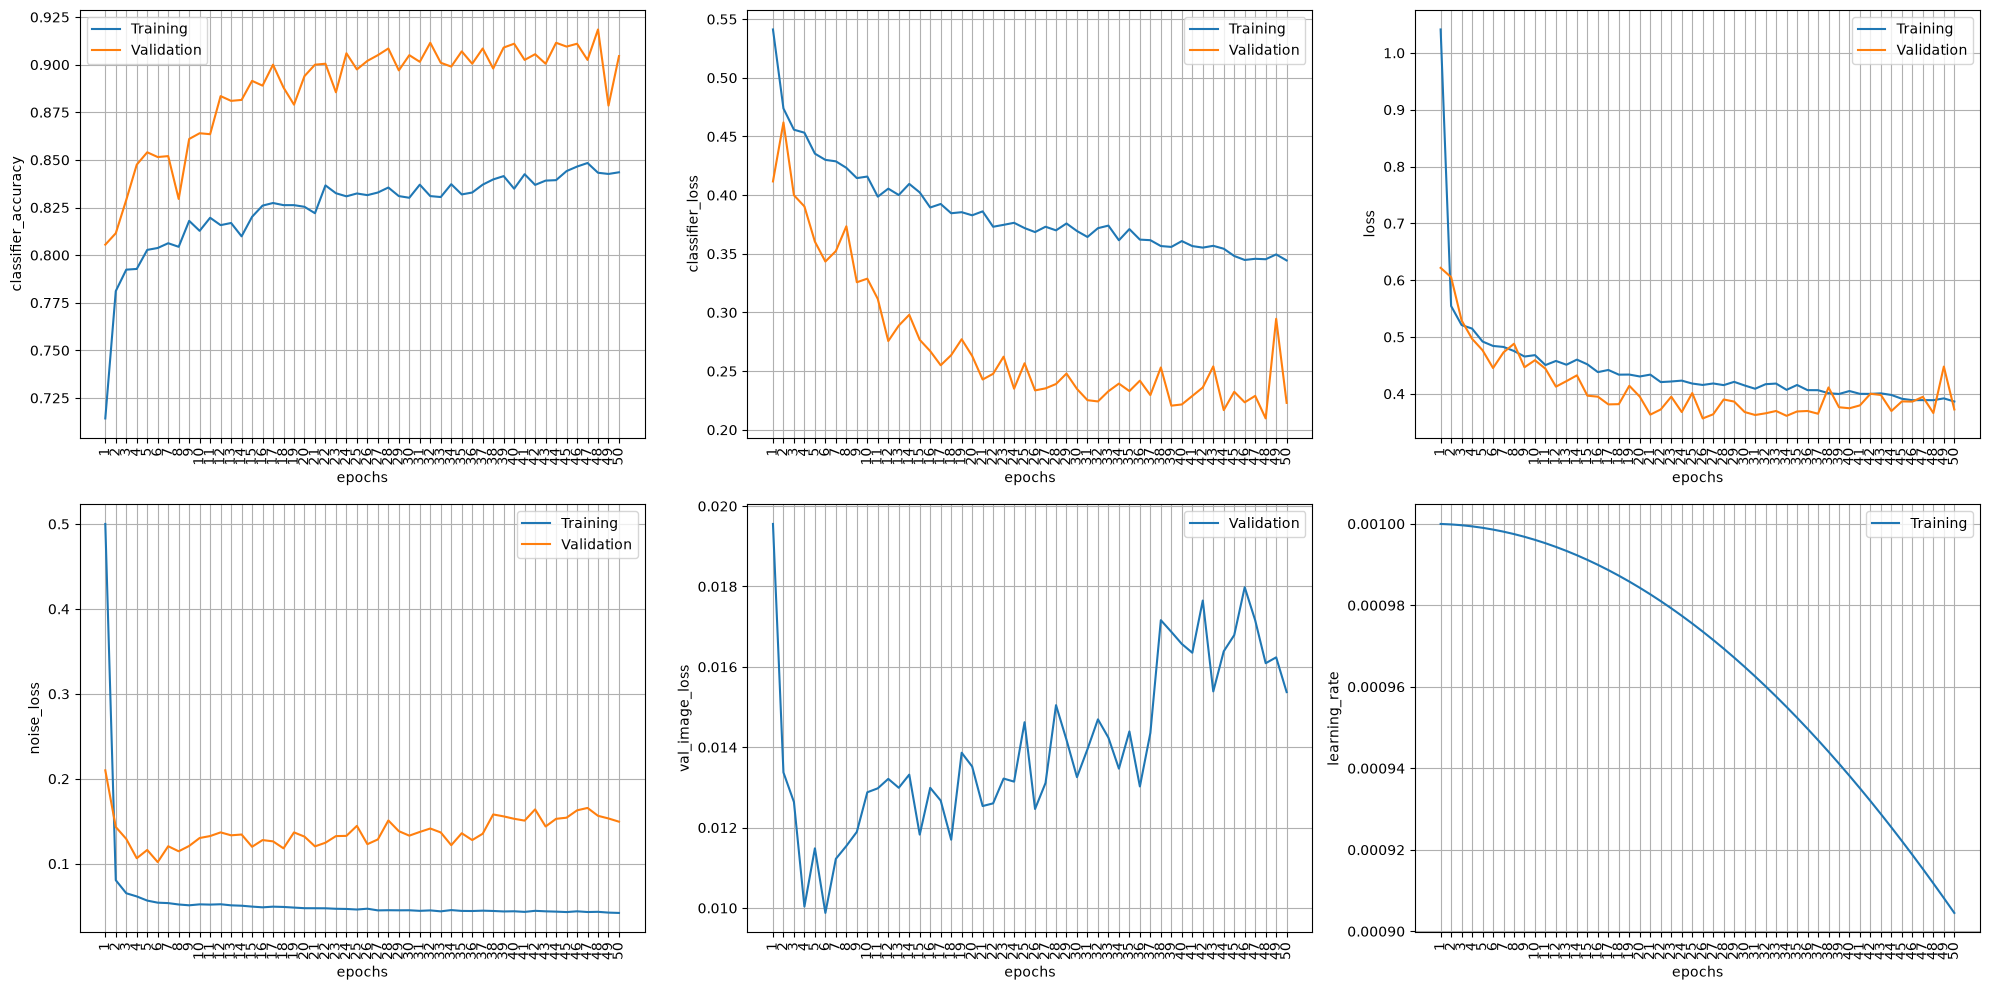

Valset evaluation:
Raw Network:
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - classifier_accuracy: 0.9045 - classifier_loss: 0.2230 - image_loss: 0.0154 - loss: 0.3724 - noise_loss: 0.1495
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 213ms/step - classifier_accuracy: 0.8376 - classifier_loss: 0.3367 - loss: 0.3921 - noise_loss: 0.0553 - val_classifier_accuracy: 0.4720 - val_classifier_loss: 5.3652 - val_image_loss: 0.0165 - val_loss: 5.5234 - val_noise_loss: 0.1582 - learning_rate: 8.7297e-04
Epoch 9/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 209ms/step - classifier_accuracy: 0.8386 - classifier_loss: 0.3327 - loss: 0.3873 - noise_loss: 0.0546 - val_classifier_accuracy: 0.4675 - val_classifier_loss: 5.3864 - val_image_loss: 0.0163 - val_loss: 5.5471 - val_noise_loss: 0.1607 - learning_rate: 8.6876e-04
Epoch 10/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 262ms/step - classifier_accuracy: 0.8309 - classifier_loss: 0.3418 - loss: 0.3979 - noise_loss: 0.0560 - val_classifier_accuracy: 0.4720 - val_classifier_loss: 5.6673 - va

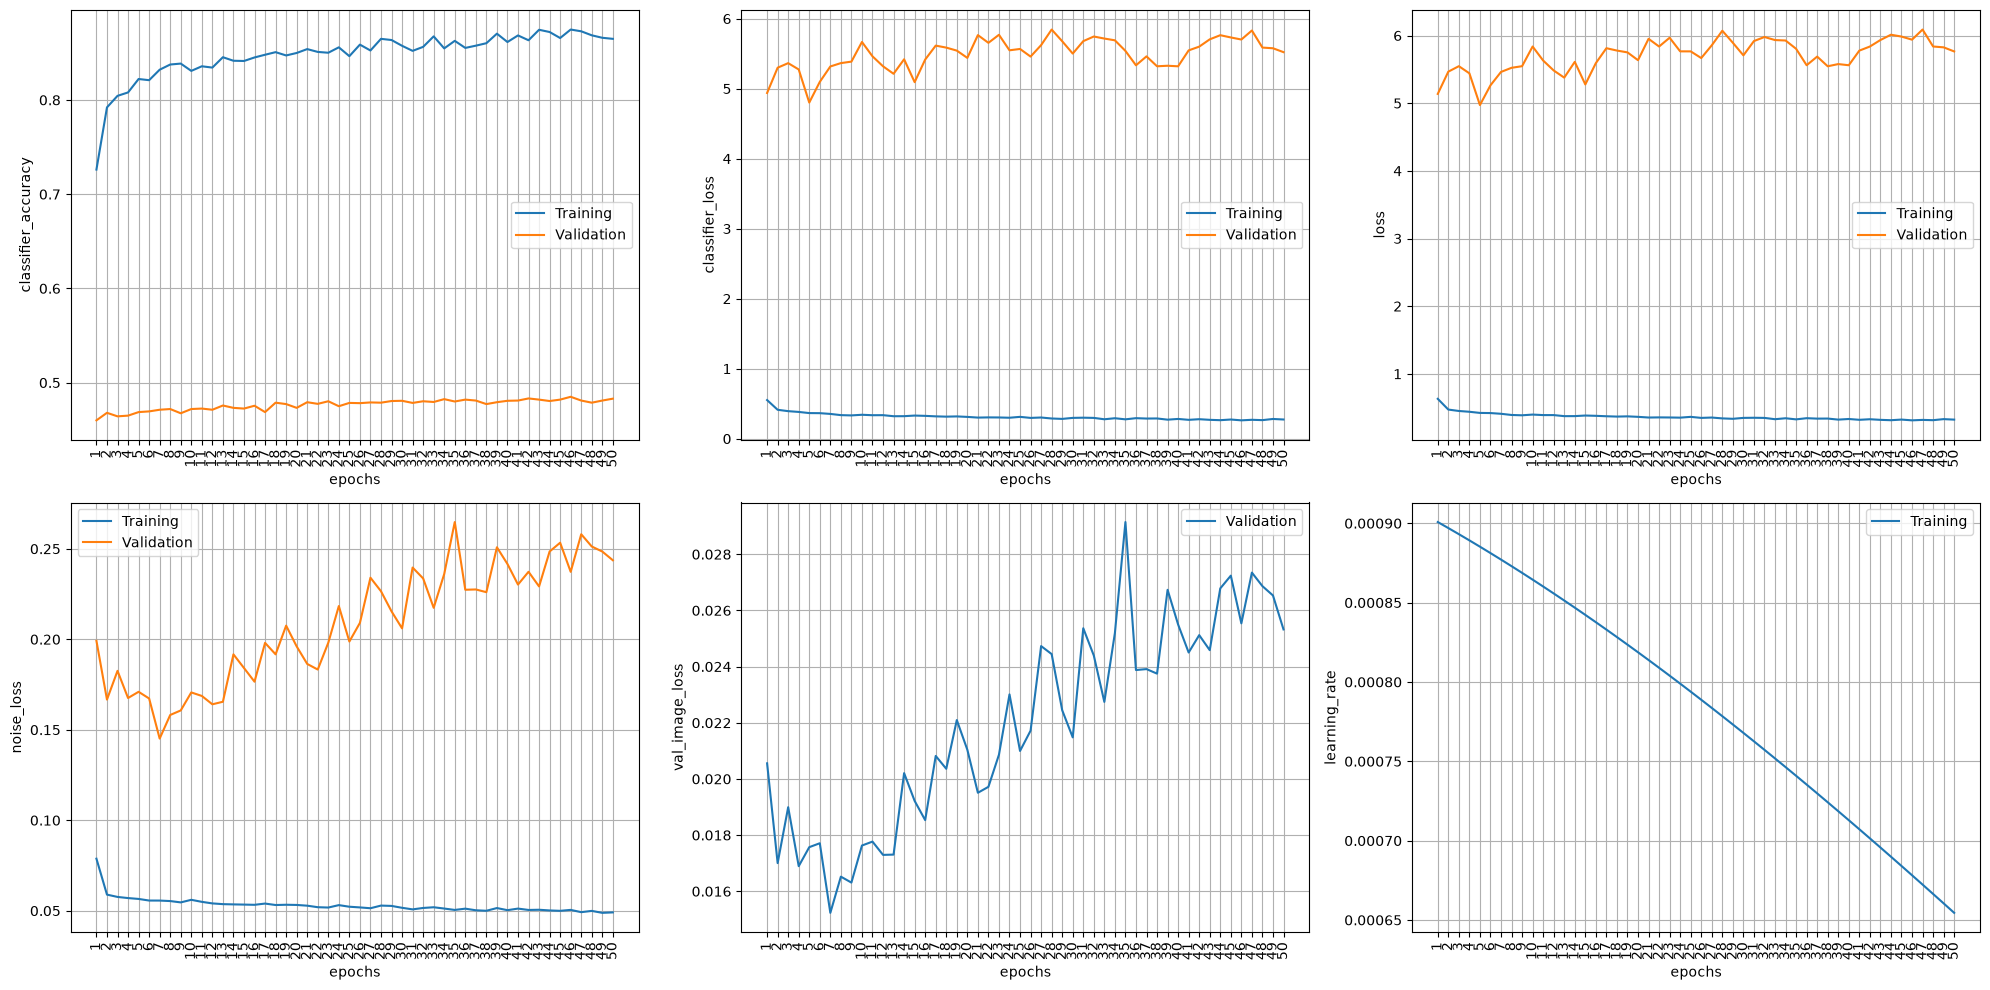

Valset evaluation:
Raw Network:
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - classifier_accuracy: 0.4830 - classifier_loss: 5.5217 - image_loss: 0.0253 - loss: 5.7654 - noise_loss: 0.2437
Step (16/16) --- Ensemble Accuracy: 0.0000


2026-10-12 19:20:49.616859: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Step (16/16) --- Ensemble Accuracy: 0.9665
Task validation accuracy: 0.4832
Task ensemble accuracy: 0.4832
---------------------------------------------------------------------------

--------------------------------------------------------------------------- 
Starting new task: 3/5, Task's class size: 2, Introduced classes so far: [4, 0, 1, 7, 8, 6]
The network has found new Classes: [8, 6]


Model: "di_t_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 64, 128)        │        75,648 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 128)            │       128,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 128)            │           896 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        39,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_cls_token           │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_distil_token        │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_feature_aggregator  │ (None, 64, 128)        │             0 │
│ (FeatureHandler)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_2_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_3_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,051,396 (11.64 MB)

 Trainable params: 2,923,324 (11.15 MB)

 Non-trainable params: 128,072 (500.56 KB)

Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 33s 267ms/step - classifier_accuracy: 0.8144 - classifier_loss: 0.4717 - loss: 0.5373 - noise_loss: 0.0657 - val_classifier_accuracy: 0.3078 - val_classifier_loss: 7.7876 - val_image_loss: 0.0306 - val_loss: 8.0726 - val_noise_loss: 0.2850 - learning_rate: 6.4852e-04
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 256ms/step - classifier_accuracy: 0.8746 - classifier_loss: 0.2906 - loss: 0.3369 - noise_loss: 0.0463 - val_classifier_accuracy: 0.3108 - val_classifier_loss: 8.0488 - val_image_loss: 0.0278 - val_loss: 8.3064 - val_noise_loss: 0.2576 - learning_rate: 6.4251e-04
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 258ms/step - classifier_accuracy: 0.8878 - classifier_loss: 0.2682 - loss: 0.3128 - noise_loss: 0.0446 - val_classifier_accuracy: 0.3093 - val_classifier_loss: 8.2114 - val_image_loss: 0.0292 - val_loss: 8.4805 - val_noise_loss: 0.2691 - learning_rate: 6.3648e-04
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 259ms/step - classifier_accuracy: 0.8821

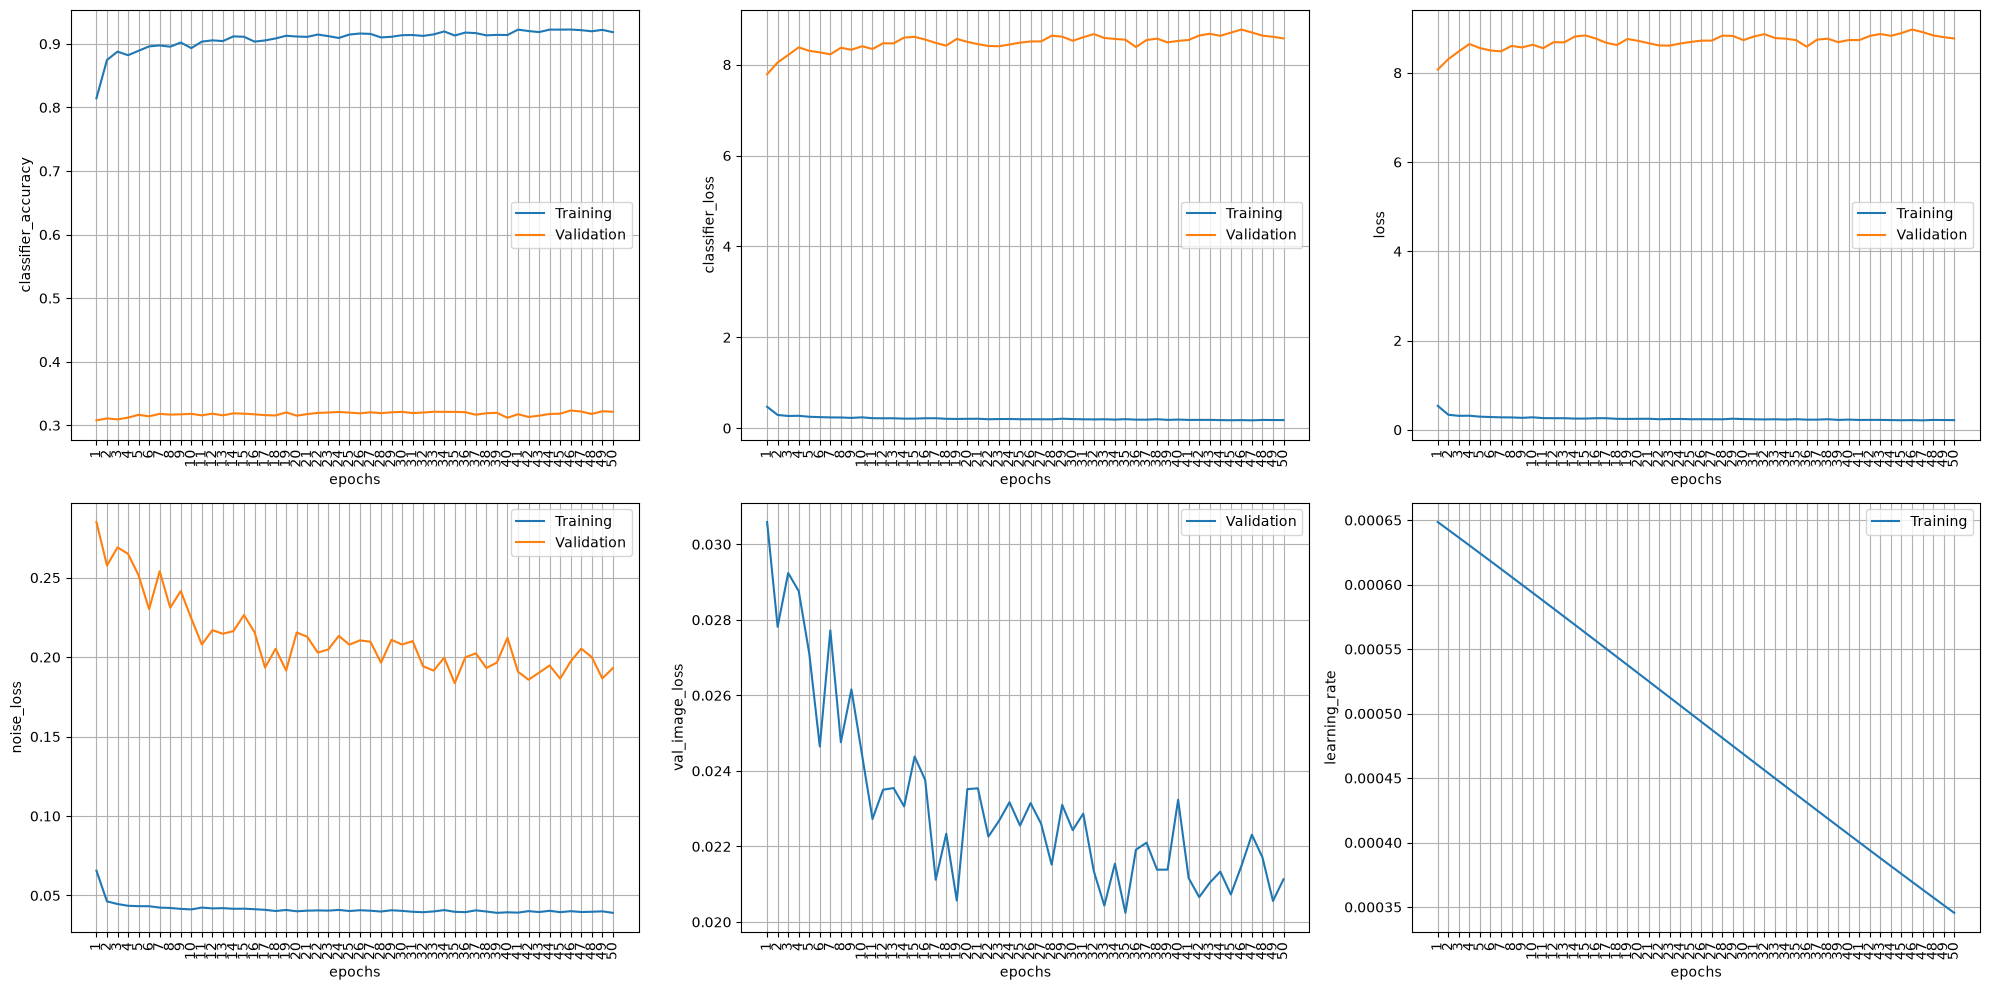

Valset evaluation:
Raw Network:
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - classifier_accuracy: 0.3213 - classifier_loss: 8.5776 - image_loss: 0.0211 - loss: 8.7707 - noise_loss: 0.1931
Step (16/16) --- Ensemble Accuracy: 0.0000
Step (16/16) --- Ensemble Accuracy: 0.0000


2026-10-12 19:46:33.129624: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Step (16/16) --- Ensemble Accuracy: 0.9625
Task validation accuracy: 0.3208
Task ensemble accuracy: 0.3208
---------------------------------------------------------------------------

--------------------------------------------------------------------------- 
Starting new task: 4/5, Task's class size: 2, Introduced classes so far: [4, 0, 1, 7, 8, 6, 2, 9]
The network has found new Classes: [2, 9]


Model: "di_t_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 64, 128)        │        75,648 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 128)            │       128,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 128)            │         1,152 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        39,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_cls_token           │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_distil_token        │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_feature_aggregator  │ (None, 64, 128)        │             0 │
│ (FeatureHandler)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_2_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_3_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,052,168 (11.64 MB)

 Trainable params: 2,924,096 (11.15 MB)

 Non-trainable params: 128,072 (500.56 KB)

Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 36s 215ms/step - classifier_accuracy: 0.6015 - classifier_loss: 1.2485 - loss: 1.3073 - noise_loss: 0.0589 - val_classifier_accuracy: 0.2059 - val_classifier_loss: 7.9253 - val_image_loss: 0.0308 - val_loss: 8.2132 - val_noise_loss: 0.2879 - learning_rate: 3.3953e-04
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 213ms/step - classifier_accuracy: 0.7839 - classifier_loss: 0.4506 - loss: 0.5030 - noise_loss: 0.0524 - val_classifier_accuracy: 0.2204 - val_classifier_loss: 7.8569 - val_image_loss: 0.0302 - val_loss: 8.1376 - val_noise_loss: 0.2807 - learning_rate: 3.3359e-04
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 252ms/step - classifier_accuracy: 0.8245 - classifier_loss: 0.3925 - loss: 0.4422 - noise_loss: 0.0497 - val_classifier_accuracy: 0.2165 - val_classifier_loss: 8.0014 - val_image_loss: 0.0273 - val_loss: 8.2620 - val_noise_loss: 0.2606 - learning_rate: 3.2768e-04
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 254ms/step - classifier_accuracy: 0.8215

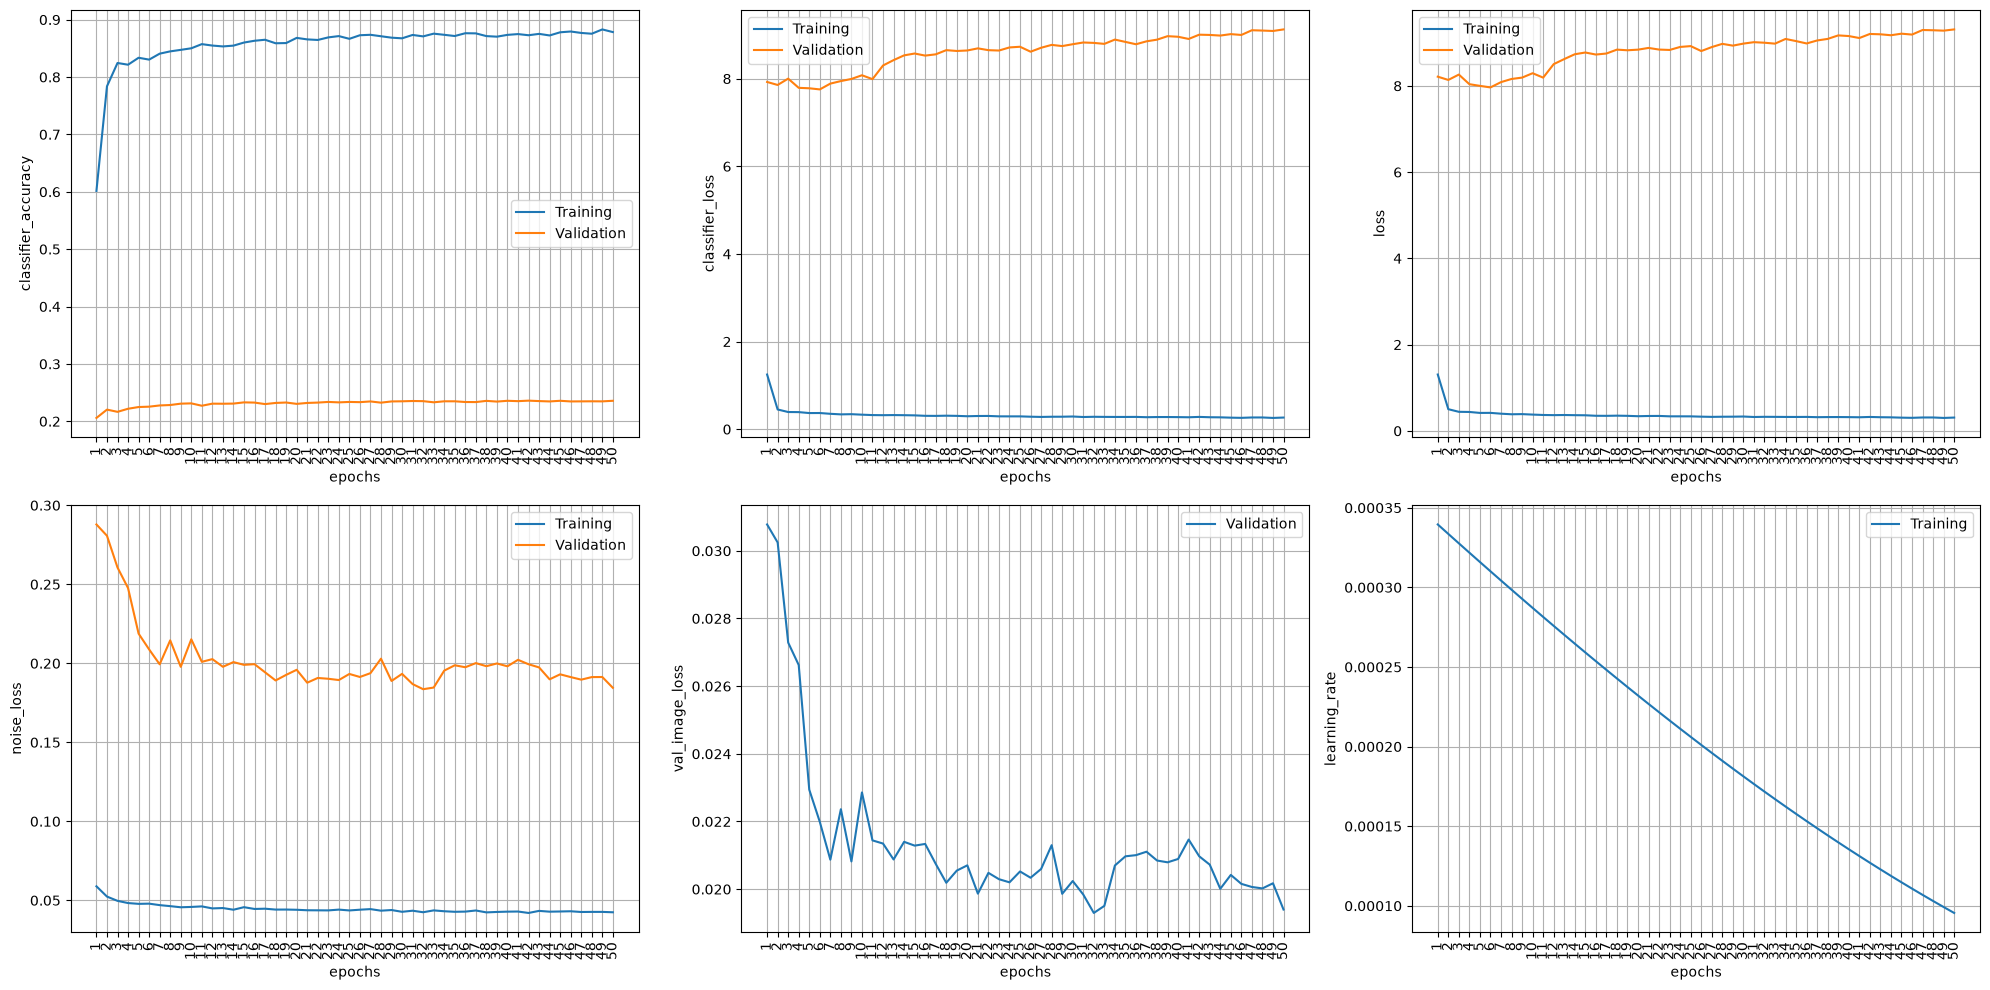

Valset evaluation:
Raw Network:
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - classifier_accuracy: 0.2358 - classifier_loss: 9.1244 - image_loss: 0.0194 - loss: 9.3089 - noise_loss: 0.1845
Step (16/16) --- Ensemble Accuracy: 0.0000
Step (16/16) --- Ensemble Accuracy: 0.0000
Step (16/16) --- Ensemble Accuracy: 0.0000
Step (16/16) --- Ensemble Accuracy: 0.9435
Task validation accuracy: 0.2359
Task ensemble accuracy: 0.2359
---------------------------------------------------------------------------

--------------------------------------------------------------------------- 
Starting new task: 5/5, Task's class size: 2, Introduced classes so far: [4, 0, 1, 7, 8, 6, 2, 9, 5, 3]
The network has found new Classes: [5, 3]


Model: "di_t_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 64, 128)        │        75,648 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 128)            │       128,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 128)            │         1,408 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 64, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        39,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_cls_token           │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_distil_token        │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_feature_aggregator  │ (None, 64, 128)        │             0 │
│ (FeatureHandler)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_2_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_3_encoder_block       │ (None, 66, 128)        │       231,046 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,052,940 (11.65 MB)

 Trainable params: 2,924,868 (11.16 MB)

 Non-trainable params: 128,072 (500.56 KB)

Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 33s 248ms/step - classifier_accuracy: 0.2729 - classifier_loss: 2.3656 - loss: 2.4146 - noise_loss: 0.0490 - val_classifier_accuracy: 0.0992 - val_classifier_loss: 8.1483 - val_image_loss: 0.0217 - val_loss: 8.3478 - val_noise_loss: 0.1995 - learning_rate: 9.1830e-05
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 199ms/step - classifier_accuracy: 0.4985 - classifier_loss: 0.7448 - loss: 0.7888 - noise_loss: 0.0439 - val_classifier_accuracy: 0.0998 - val_classifier_loss: 8.8582 - val_image_loss: 0.0214 - val_loss: 9.0564 - val_noise_loss: 0.1982 - learning_rate: 8.8234e-05
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 196ms/step - classifier_accuracy: 0.5211 - classifier_loss: 0.7228 - loss: 0.7659 - noise_loss: 0.0431 - val_classifier_accuracy: 0.1095 - val_classifier_loss: 9.1179 - val_image_loss: 0.0211 - val_loss: 9.3140 - val_noise_loss: 0.1961 - learning_rate: 8.4702e-05
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 195ms/step - classifier_accuracy: 0.5275

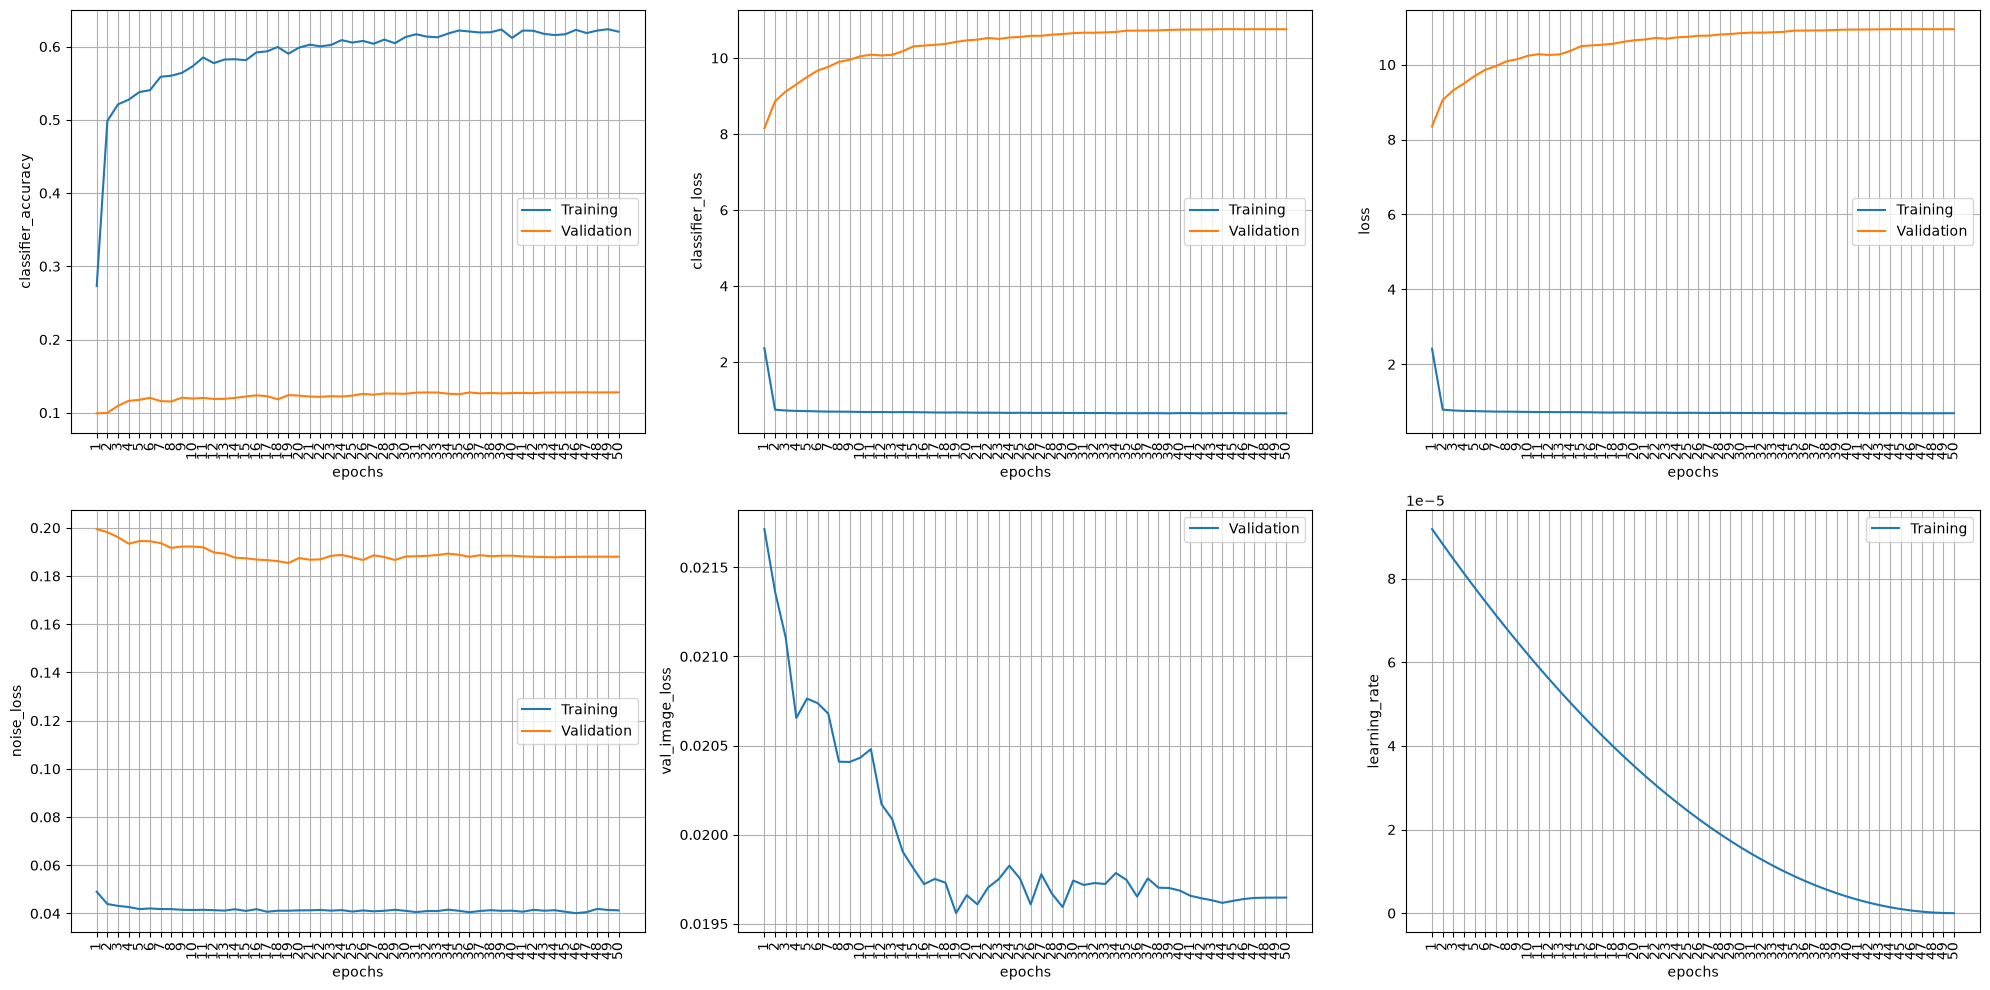

Valset evaluation:
Raw Network:
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - classifier_accuracy: 0.1278 - classifier_loss: 10.7567 - image_loss: 0.0196 - loss: 10.9447 - noise_loss: 0.1880
Step (16/16) --- Ensemble Accuracy: 0.0000


2026-10-12 20:36:07.655822: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Step (16/16) --- Ensemble Accuracy: 0.0000
Step (16/16) --- Ensemble Accuracy: 0.0000
Step (16/16) --- Ensemble Accuracy: 0.0000
Step (16/16) --- Ensemble Accuracy: 0.6510
Task validation accuracy: 0.1302
Task ensemble accuracy: 0.1302
---------------------------------------------------------------------------



In [7]:
# The helper refuses a second training call for the same prepared context.
history = train_reference(config, context)

## 6. Save and inspect results

Inspect final overall accuracy, the per-task evaluation table, and available forgetting/backward-transfer results from the task sequence. Poor retention is an observation to measure, not an assumed result.

In [8]:
summary, per_task = finish_reference(config, context, history)
display(summary)
display(per_task)
print("Saved results:", context["run_dir"])

{'benchmark': 'naive_sequential',
 'dataset': 'cifar10',
 'seed': 17,
 'evaluation_split': 'validation',
 'metric_scale': 'fraction',
 'final_average_accuracy': 0.13020000457763672,
 'average_incremental_accuracy': 0.41753166735172276,
 'average_forgetting': 0.9474999904632568,
 'backward_transfer': -0.9474999904632568,
 'accuracy_source': 'ensemble',
 'ensemble_accuracy_kwargs': {'network_name': 'raw',
  'max_t': 256,
  't_range_drop_rate': 0.75,
  'clf_distil_acc_coef': 0.0,
  'clf_acc_coef': 1.0},
 'training_seconds': 7296.982396826148,
 'training_seconds_scope': 'Entire native train_model call, including any task evaluation, reporting and checkpoint writes; excludes preparation and final reference reporting.',
 'native_results_path': '/workspace/Continual-Learning-with-Diffusion-Vision-Transformers/files/results/thesis_route_one/reference_benchmarks/cifar10/naive_sequential/seed-17-20261012T184945Z-fadcf0ca/native/2026-10-12_18-49-57 naive_sequential-cifar10-seed-17',
 'objective':

,task,original_classes,accuracy,accuracy_percent
0,1,"[4, 0]",0.000,0.000000
1,2,"[1, 7]",0.000,0.000000
2,3,"[8, 6]",0.000,0.000000
3,4,"[2, 9]",0.000,0.000000
4,5,"[5, 3]",0.651,65.100002


Saved results: /workspace/Continual-Learning-with-Diffusion-Vision-Transformers/files/results/thesis_route_one/reference_benchmarks/cifar10/naive_sequential/seed-17-20261012T184945Z-fadcf0ca


## Interpretation and cleanup

Treat this result as a naive sequential lower reference. It is not the minimum possible accuracy, and a continual-learning intervention can perform worse. Compare identical dataset splits, seeds, class orders, task groups, and evaluation conventions.

After the final cell succeeds, **save this notebook with its outputs, then restart its kernel** to release its training state before running another notebook. Result artifacts are saved separately in the printed folder.

See the [reference definitions and comparison limits](README.md#offline-and-naive-reference-benchmarks).